# Data Collection

## 1. Collecting and reviewing the data
In this notebook we open the raw data for the first time and look through what it contains. At this point we aren't doing any cleaning or removal. The point is to understand every column: what it contains, what type it's supposed to be, whether we need it at all and what problems it has.

We're working with two datasets:
- **BFRO** - reports of Bigfoot sightings in the USA and Canada.
- **Loch Ness** - reports of the Loch Ness monster sightings.

For every dataset we first check where it comes from and who gathered it. After that we look through the size, data types and missing values. Finally, we go through the data column by column.

The decisions will be written in two files: `config/bfro_columns.json` and `config/loch_ness_columns.json`. For every column they record what it is, whether we'll keep it and why. The next notebook (`02_data_cleaning.ipynb`) will tidy up the data according to these rules.

## 2. Setup
Imports and project paths. `src/paths.py` defines the project folders (`RAW`, `PROCESSED`, `CONFIG`) relative to the repository root, so the notebook works regardless of where it is run from.

In [335]:
import sys
sys.path.append('..') # look for imports in the parent directory

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.paths import RAW, CONFIG

pd.set_option('display.max_columns', None) #set pandas option to display all columns in a DataFrame

print(f"Reading data from {RAW}")
print(f"Reading config from {CONFIG}")

Reading data from C:\dev\MonstersInTheData\data\raw
Reading config from C:\dev\MonstersInTheData\config


## 3. BFRO (Bigfoot)

### 3.1. Origin of the data

The reports were collected by the Bigfoot Field Researchers Organization (BFRO) - an organization in which people send their personal accounts of sighting Bigfoot. Timothy Renner downloaded the reports from their site, added coordinates and filled every report with information about the weather (temperature, humidity, Moon phase, etc.) for the corresponding date and place from the Dark Sky API. The version we're working with is from TidyTuesday (13.09.2022).

NB: `readme.md` from TidyTuesday doesn't give information about the columns - the description of each is just its name. For this reason we retrieve the significance of the columns from the BFRO website and from what we can see in the data itself.

Report classes (from BFRO):
- **A** - a clear sighting which has a small likelihood to be confused with another animal;
- **B** - from a great distance, in poor lighting or without a clear view; all sound-only reports are in B;
- **C** - second or third-hand reports; most aren't published.

The class measures how easy it is to confuse something, not whether the witness is honest.


In [336]:
# Loading and first looks
bfro = pd.read_csv(RAW / "bfro" / "bigfoot.csv")

print(f"bfro has shape {bfro.shape}")
bfro.head()

bfro has shape (5021, 28)


,observed,location_details,county,state,season,title,latitude,longitude,date,number,classification,geohash,temperature_high,temperature_mid,temperature_low,dew_point,humidity,cloud_cover,moon_phase,precip_intensity,precip_probability,precip_type,pressure,summary,uv_index,visibility,wind_bearing,wind_speed
0,I was canoeing on the Sipsey river in Alabama....,NaN,Winston County,Alabama,Summer,NaN,NaN,NaN,NaN,30680.0,Class B,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Ed L. was salmon fishing with a companion in P...,East side of Prince William Sound,Valdez-Chitina-Whittier County,Alaska,Fall,NaN,NaN,NaN,NaN,1261.0,Class A,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,"While attending U.R.I in the Fall of 1974,I wo...","Great swamp area, Narragansett Indians",Washington County,Rhode Island,Fall,Report 6496: Bicycling student has night encou...,41.45,-71.5,1974-09-20,6496.0,Class A,drm5ucxrc0,78.17,73.425,68.68,65.72,0.86,0.86,0.16,0.0,0.0,NaN,1020.61,Foggy until afternoon.,4.0,2.75,198.0,6.92
3,"Hello, My name is Doug and though I am very re...",I would rather not have exact location (listin...,York County,Pennsylvania,Summer,NaN,NaN,NaN,NaN,8000.0,Class B,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,It was May 1984. Two friends and I were up in ...,"Logging roads north west of Yamhill, OR, about...",Yamhill County,Oregon,Spring,NaN,NaN,NaN,NaN,703.0,Class B,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [337]:
print(f"The dataset has the following column types:\n{bfro.dtypes}")

The dataset has the following column types:
observed                  str
location_details          str
county                    str
state                     str
season                    str
title                     str
latitude              float64
longitude             float64
date                      str
number                float64
classification            str
geohash                   str
temperature_high      float64
temperature_mid       float64
temperature_low       float64
dew_point             float64
humidity              float64
cloud_cover           float64
moon_phase            float64
precip_intensity      float64
precip_probability    float64
precip_type               str
pressure              float64
summary                   str
uv_index              float64
visibility            float64
wind_bearing          float64
wind_speed            float64
dtype: object


## 3.2 First looks

The dataset has 5021 rows and 28 columns. Every row is a single report. Most columns have been read with the correct type: the coordinates and the meteo data are numbers, while the text descriptions are text.

What needs to change:
- **`date`** is read as text. It needs to become a date, but first we'll check what formats it has.
- **`number`** is the BFRO report number, i.e. an integer but it's read as `float64`. Normally this means that there are missing values (NaN can't be an integer) - we'll check in a moment.
- **`classification`, `season`, `state`, `precip_type`** are text but have little in the way of differing values. These are categories, not free text.

### Examine `number`

`number` is read as `float64` despite the report numbers needing to be integers. We'll check two things: whether there are missing values (that would explain the float) and whether all values are integers. If both checks are okay, the column can become `int`.

In [338]:
# Print the number of missing values in the 'number' column
print(f"Missing number: {bfro.number.isna().sum()}")

# print whether all non-missing values in the 'number' column are integers
print(f"All numbers are integers: {(bfro.number.dropna() % 1 == 0).all()}")

Missing number: 0
All numbers are integers: True


Nothing's missing and all are integers, so we'll change it to `int`. It was read as a float, because in the CSV the numbers are written with a decimal point (e.g. `30680.0`) - the file was likely exported from R, where the column is of type `double`.

### Counting different values

Some text columns are probably not free text, but categories - a small range of values that repeat. We'll examine how many different values each one of them has to determine which will become categories.

In [339]:
bfro[["classification", "season", "state", "county", "precip_type"]].nunique() # the number of unique values in each of the categorical columns

classification       3
season               5
state               49
county            1037
precip_type          2
dtype: int64

- `classification` (3 values), `precip_type` (2) and `state` (49) have little in the way of differing values and will become categories.
- `season` has 5 values, while the seasons are 4. We'll see what the fifth one is in the next section.
- `county` has 1037 different values. That's too many for a category, so we'll leave it as text.

### Values in the categorical columns

For each column with a few values we'll not only see what they are but their frequency as well. With `dropna=False` the missing values will also be counted so we can see how many reports don't have a value.

In [340]:
# Print the unique values in the categorical columns
for col in ["classification", "season", "precip_type"]:
    print(bfro[col].value_counts(dropna=False), "\n")

classification
Class B    2510
Class A    2481
Class C      30
Name: count, dtype: int64 

season
Summer     1867
Fall       1492
Spring      825
Winter      745
Unknown      92
Name: count, dtype: int64 

precip_type
NaN     3298
rain    1562
snow     161
Name: count, dtype: int64 



- Class C only has 30 reports (0.6%) because BFRO rarely publishes them. The comparisons between classes will be A vs. B. C is too small to draw conclusions from.
- The fifth value in `season` is "Unknown" (92 reports). This is a missing value written as text (that's why `isna()` didn't catch it), so we'll convert it to NaN.
- `precip_type` is missing from 3298 reports. We'll examine this in the next step.

### Precipitation type

We'll check if the missing values mean "no precipitation" or "no meteorological data" by looking at the intensity of the precipitation (`precip_intensity`) in these reports.

In [341]:
# Check precipitation types
no_type = bfro.precip_type.isna()
print(f"precip_type NaN, intensity 0: {(no_type & (bfro.precip_intensity == 0)).sum()}")
print(f"precip_type NaN, intensity NaN: {(no_type & bfro.precip_intensity.isna()).sum()}")
print(f"precip_type NaN, intensity > 0: {(no_type & (bfro.precip_intensity > 0)).sum()}")

precip_type NaN, intensity 0: 1646
precip_type NaN, intensity NaN: 1652
precip_type NaN, intensity > 0: 0


Those are two different cases: in 1646 the precipitation intensity is 0, i.e. it didn't precipitate; the other 1652 lack meteorological data. There aren't any reports with precipitation that don't have a type.

### Season vs. Date

We'll examine how many of the reports with an "Unknown" season have a date, i.e. whether the season can be derived from it.

In [342]:
# Check unknown seasons that might have dates
unknown_season = bfro.season == "Unknown"
print(f"Unknown season but has date: {bfro[unknown_season].date.notna().sum()}")

Unknown season but has date: 64


Of the 92 reports with "Unknown", 64 have a date, which means that for them the season could be derived from the date. Only 28 truly remain without a season.

Before we decide, we need to check how BFRO determines seasons. For example, is December winter or is it autumn until the 21st of December? We'll check in the reports that have both a season and a date.

In [343]:
known = bfro[(bfro.season != "Unknown") & (bfro.date.notna())]
pd.crosstab(pd.to_datetime(known.date).dt.month, known.season, dropna=False)

season,Fall,Spring,Summer,Winter
date,,,,
1,26,10,22,178
2,9,14,21,117
3,10,100,13,45
4,11,200,17,5
5,3,230,37,10
6,9,65,294,3
7,10,13,474,4
8,34,4,423,6
9,279,5,121,1


The table shows that **the season isn't derived from the date**. Every month has reports in all four seasons.

If we judge by the meteorological seasons (December-February as Winter etc.), around 81% of the reports match (3229 of 3981). The remaining around 19% (752 reports) don't match and are two kinds:
- **On the border between seasons**, for example 45 reports "Winter" in March, 121 "Summer" in September, 74 "Winter" in November. That might be due to a different definition of what a season is (astronomically, with the 21st) or just how the witness felt the weather at the time.
- **Clearly incompatible**, for example 22 reports "Summer" in January or 10 "Fall" in July. Here the date or the season is wrong.

`season` and `date` are two separate fields which the witnesses fill out themselves, and they don't necessarily match. Before deciding which one to trust, we'll read a couple of the incompatible reports. The text in `observed` may hold the truth.

In [344]:
month = pd.to_datetime(known.date).dt.month
odd = known[(month.isin([12, 1, 2])) & (known.season == "Summer")]

for i, row in odd.head(5).iterrows():
    print(f"[{i}] date={row.date}, season={row.season}")
    print(row.observed[:600])
    print("-" * 80)

[14] date=1971-12-15, season=Summer
This happened summertime early 70's (I think 71, 72?).   Me, my husband at the time, and my two brothers hiked into Lilly Pad and Crater Lakes, Stillwater County, Montana.  It borders Custer National Forest, north of the East Fork of Fiddler Creek. There were no other cars in the parking lot so absolutely there was no one else up in that area or encountered.  It is a very remote and high mountainous area.  Lilly Pad is full of lilly pads, per its name.  At the time I thought it strange that we didn't see any moose there. When we left Lilly Pad, we climbed the side of the mountain, a very rocky
--------------------------------------------------------------------------------
[18] date=2005-12-21, season=Summer
I was coming home after work about 9:30 to 10 pm heading north on ridge road.  It recently rained. Something rain across the road on two legs.  It was about 50 to 100 yards away.  It appeared to be about as tall as the hood of my car. It stopped 

That's an important clue. In at least three out of the five reports **the date isn't that of the sighting**:

| Report | `date` | What the text says | Conclusion |
| --- | --- | --- | --- |
| 14 | 1971-12-15 | "summertime early 70's (I think 71, 72?)" | The season is correct. The year is approximate, while the day and month look filled. |
| 18 | 2005-12-21 | "It recently rained" | No data about the season, it can't be determined. |
| 63 | 2004-01-18 | A kid, about 11-12, at a Boy Scout camp, eating leaves. | Probably summer, but there's no year in the text. |
| 176 | 2005-01-06 | "occured in 1975 when I was 14" | A difference of 30 years. The date is different, probably when the report was filed. |
| 220 | 2009-01-25 | "that summer evening long ago" | The season looks correct, but the date looks like a report date. |


The conclusion is more serious than mismatching seasons. **In part of the reports `date` is probably the date the report was filed, not that of the actual sighting.** This affects every analysis by years, not just by season. Five reports aren't enough to tell how frequent that is. We'll approach it systematically: find the years mentioned in the text and compare them against those in `date`.

In [345]:
years_in_text = bfro.observed.fillna("").str.findall(r"\b(1[89]\d\d|20[0-2]\d)\b")
date_year = pd.to_datetime(bfro.date, errors="coerce").dt.year

has_both = years_in_text.str.len().gt(0) & date_year.notna()

year_matches = pd.Series(
    [str(int(y)) in yrs if pd.notna(y) else False
     for y, yrs in zip(date_year, years_in_text)],
    index=bfro.index,
)
mismatched_years = has_both & ~year_matches

print(f"Reports with a date and year in the text: {has_both.sum()}")
print(f"... where the date's year does not match the year in the text: {mismatched_years.sum()}")


Reports with a date and year in the text: 1582
... where the date's year does not match the year in the text: 328


The check is crude. An observation can mention a different year (e.g. "I moved here in 1990"), so the mismatch isn't always an error. It gives an upper bound and shows whether the problem is frequent or an outlier. We'll read a couple of the mismatched reports and see which of the two it is.

In 328 out of 1582 reports (around 21%) that have both a date and a year in the observation, the year in `date` isn't among the years in the text. That's an upper bound, but the problem clearly isn't an outlier.

The report is filed after the sighting, so in the typical case the date is later than all the years mentioned in the text. We check how many such reports there are and read three random ones (with a fixed `random_state`, so the sample is the same on every run).

In [346]:
max_year_in_text = years_in_text.apply(lambda yrs: max(map(int, yrs)) if yrs else np.nan)
date_later = has_both & (date_year > max_year_in_text + 1)
print(f"Date is later than every year in the text: {date_later.sum()}")

for i in bfro[date_later].sample(3, random_state=0).index:
    print(f"[{i}] date={bfro.date[i]}, years in text={years_in_text[i]}")
    print(bfro.observed[i][:400])
    print("-" * 80)

Date is later than every year in the text: 213
[4688] date=2017-01-24, years in text=['1953']
In 1953 I was a 10 year old girl living in George Field (Barracks), IL. George Field was a WWII air base for pilot training & the barracks housed airmen and brass. After the war the Barracks were converted to civilian apartments & my family lived in one. George Field was in an extremely remote area between Vincennes, Indiana & Lawrenceville, Illinois. The Wabash River was east close to Vincennes a
--------------------------------------------------------------------------------
[713] date=2004-08-29, years in text=['1943']
I would be happy to send you a copy of a colored picture I drew when I was 5 years old back in 1943 of what possibly could have been a bigfoot.  I was lost out in the woods while camping with my parents somewhere in central Ohio and this large female ape-like creature put me back in our camp. Then I started screaming and my parents who were out looking for me heard me and cam

In 213 out of 1582 reports (around 13%), the date is later than all the years mentioned in the observation. In all three reports we read, the witness describes an event 16 to 64 years earlier (1953, 1943, 1988), but the date is from 2004–2017 - most likely the date of filing the report, not that of the sighting. In the third observation, the exact moment is given ("early July of 1988"), but the date is 2004-10-31.

That's a more reliable estimate than the 328, though not an exact one: a witness may mention only an earlier, unrelated year (e.g. "I was born in 1953"). In reports without a year in the observation the same thing probably happens too, but it can't be checked.

Both the five reports we read and the systematic check show that `date` is often the date of filing the report, not that of the sighting. In these cases `season` is more dependable.

For this reason:
- **We won't fill in the 92 "Unknown" from the date** - the date isn't always that of the sighting.
- **For the analyses by season we'll use `season`.**
- **The date is undependable for analyses by years** - in around 13% of the reports with a year in the observation, it's the date of report filing, not of the sighting. We'll mark these reports and do the analyses by years with and without them.

### Format and accuracy of the dates

We'll check two things. First, whether all the dates are in the same format (`YYYY-MM-DD`) - if some dates are only years or years and months, the length of the string will be different. Second, whether some days in the month appear suspiciously frequently. If the witness doesn't remember the exact day, the 1st or the 15th is often written in its place - then the day isn't real.

In [347]:
print(bfro.date.str.len().value_counts(dropna=False))

date
10.0    4045
NaN      976
Name: count, dtype: int64


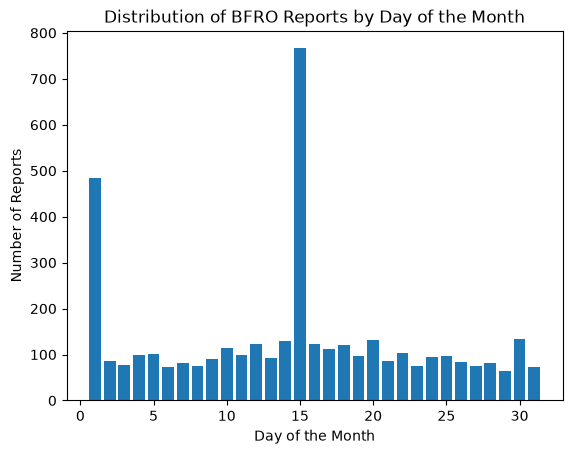

In [348]:
day = pd.to_datetime(bfro.date, errors="coerce").dt.day

# Count how many reports fall on each day of the month (reports without a date are excluded)
day_counts = day.value_counts().sort_index()

plt.bar(day_counts.index, day_counts.values)
plt.xlabel("Day of the Month")
plt.ylabel("Number of Reports")
plt.title("Distribution of BFRO Reports by Day of the Month")
plt.show()


In [349]:
# Expected count for an ordinary day: the mean of all other days (29-31 excluded, as not every month has them)
typical = day_counts.drop([1, 15, 29, 30, 31]).mean()
for d in [1, 15]:
    print(f"Day {d}: {day_counts[d]} reports, expected ~{typical:.0f}, excess ~{day_counts[d] - typical:.0f}")

Day 1: 485 reports, expected ~97, excess ~388
Day 15: 766 reports, expected ~97, excess ~669


All 4045 dates are in the full format (`YYYY-MM-DD`), while 976 reports don't have a date. The inaccuracy isn't visible from the format - it's hidden in dates that look complete.

The graph shows clear peaks on the 1st and the 15th: 485 and 766 reports, when the expected count for an ordinary day is around 97. The excess of around 1057 reports (around 26% of all dates) is likely due to dates where the witness only remembered the month, while the day was filled. We can't determine exactly which these are, as some of the reports on these dates are real.

If the witness only remembered the year, by the same logic the month may be filled as January. We'll examine the report count by months. Months also differ naturally (summer has more reports), so a January peak would be suspicious precisely because winter has the fewest reports.

In [350]:
month_all = pd.to_datetime(bfro.date, errors="coerce").dt.month
month_all.value_counts().sort_index()

date
1.0     251
2.0     162
3.0     168
4.0     235
5.0     286
6.0     389
7.0     505
8.0     475
9.0     409
10.0    545
11.0    400
12.0    220
Name: count, dtype: int64

January has 251 reports - more than December (220) and much more than February (162), despite all three being winter months. Compared against the average for December and February (around 191), that's around 60 reports more. Some of these are probably dates where the witness only remembered the year. The effect is much smaller than that of the days, so we won't mark January separately, but we'll note it as a limitation.

Conclusions about the dates:
- **The day is unreliable in around 26% of the reports with a date.** We'll mark the reports on the 1st and the 15th (`day_suspect`) - a total of 1251 reports (31% of the reports with a date). Around 194 of them ($2 \times 97$) probably have a real day, but it's better to exclude a few real ones than to include over 1000 filled ones.
- **The meteorological data and `moon_phase` for these reports are for the wrong day** - they were retrieved based on the date. The analyses that use them will be done with and without the marked reports.